In [ ]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled")
    except RuntimeError as e:
        print(e)

Memory growth enabled


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
pip install importlib-resources

In [ ]:
def plot_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history.history['accuracy'], label='train')
    ax[0].plot(history.history['val_accuracy'], label='validation')
    ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(history.history['loss'], label='train')
    ax[1].plot(history.history['val_loss'], label='validation')
    ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.show()

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds

IMG_SIZE = (128, 128)
BATCH = 8
AUTOTUNE = tf.data.AUTOTUNE

# Load dataset builder / info without fully expanding it into RAM
ds = tfds.load("cats_vs_dogs", split="train", as_supervised=True)

# Shuffle with a buffer size instead of loading all 23,000 items at once
ds = ds.shuffle(buffer_size=1000, seed=42, reshuffle_each_iteration=True)

def prep(img, label):
    img = tf.image.resize(img, IMG_SIZE)
    # Ensure images are cast to float32 and normalized to [0, 1] range to save activation memory
    img = tf.cast(img, tf.float32) / 255.0
    label = tf.expand_dims(tf.cast(label, tf.float32), -1)
    return img, label

# Streamlined pipeline: map -> batch -> prefetch (NO .cache() to protect system RAM)
train_ds = (
    ds.take(2000)
    .map(prep, num_parallel_calls=AUTOTUNE)
    .batch(BATCH)
    .prefetch(AUTOTUNE)
)

val_ds = (
    ds.skip(2000)
    .take(1000)
    .map(prep, num_parallel_calls=AUTOTUNE)
    .batch(BATCH)
    .prefetch(AUTOTUNE)
)

In [ ]:


# Remove .cache() so it doesn't hoard system RAM
train_ds = (
    ds.take(2000)
    .map(prep, num_parallel_calls=AUTOTUNE)
    .batch(BATCH)
    .prefetch(AUTOTUNE)
)

val_ds = (
    ds.skip(2000)
    .take(1000)
    .map(prep, num_parallel_calls=AUTOTUNE)
    .batch(BATCH)
    .prefetch(AUTOTUNE)
)

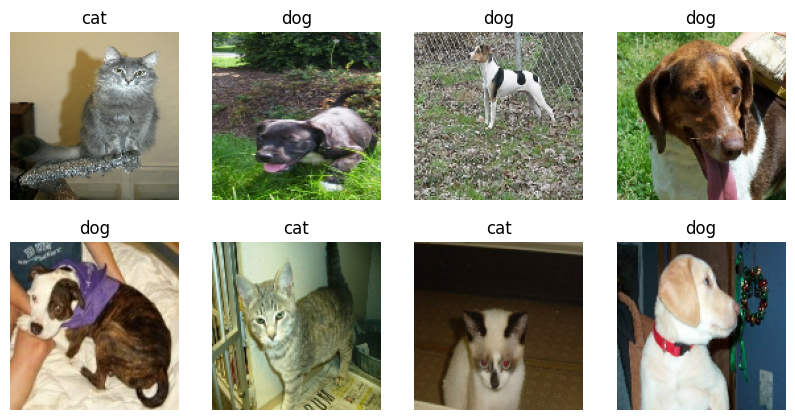

In [ ]:
# Peek at a few training images (adjusting grid to fit BATCH = 8)
class_names = ['cat', 'dog']

plt.figure(figsize=(10, 5))
for images, labels in train_ds.take(1):
    num_images = min(len(images), 8)
    for i in range(num_images):
        plt.subplot(2, 4, i + 1)
        # Displaying normalized float32 images directly in [0.0, 1.0] range
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.show()

In [ ]:
from tensorflow.keras import layers, models

def create_lightweight_model():
    model = models.Sequential([
        # Input block
        layers.Input(shape=(128, 128, 3)),

        # Block 1
        layers.Conv2D(16, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Global Average Pooling replaces massive Flatten + Dense layers to slash parameters
        layers.GlobalAveragePooling2D(),

        # Small dense layer
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),

        # Output layer (Binary classification)
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

model_bin = create_lightweight_model()
model_bin.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,809 (108.63 KB)

 Trainable params: 27,809 (108.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model_bin.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.5865 - loss: 0.6675 - val_accuracy: 0.6290 - val_loss: 0.6483
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.5915 - loss: 0.6653 - val_accuracy: 0.6240 - val_loss: 0.6508
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6160 - loss: 0.6491 - val_accuracy: 0.6240 - val_loss: 0.6417
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.6190 - loss: 0.6536 - val_accuracy: 0.6700 - val_loss: 0.6320
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.6380 - loss: 0.6349 - val_accuracy: 0.6400 - val_loss: 0.6459
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.6445 - loss: 0.6297 - val_accuracy: 0.6520 - val_loss: 0.6189
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.6645 - loss: 0.6245 - val_accuracy: 0.6450 - val_loss: 0.6244
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.6615 - loss: 0.6265 - val_ac

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.6620 - loss: 0.6073
Part A validation accuracy: 0.6620
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


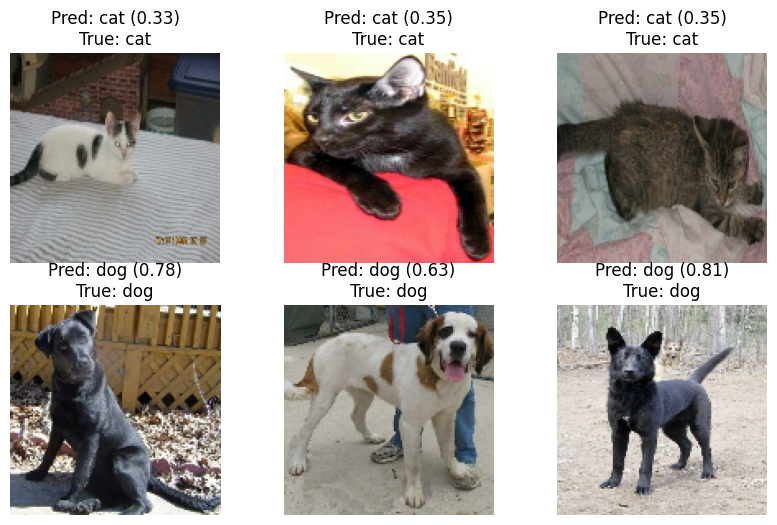

In [ ]:
loss, acc = model_bin.evaluate(val_ds)
print(f"Part A validation accuracy: {acc:.4f}")

# Predictions on a few validation images
for images, labels in val_ds.take(1):
    probs = model_bin.predict(images[:6]).ravel()
    plt.figure(figsize=(10, 6))
    for i in range(6):
        pred = int(probs[i] > 0.5)           # threshold at 0.5
        plt.subplot(2, 3, i + 1)
        # Displaying normalized float32 images directly in [0.0, 1.0] range
        plt.imshow(images[i].numpy())
        plt.title(f"Pred: {class_names[pred]} ({probs[i]:.2f})\nTrue: {class_names[int(labels[i][0])]}")
        plt.axis("off")
    plt.show()